# Mini Project: Mall Customer Segmentation
**Subject:** Machine Learning / Business Analytics  
**Topic:** K-Means Clustering

**Aim:** Apply K-Means to group mall customers using Age, Annual Income, and Spending Score; visualize the customer groups; and label them as **Low Spenders**, **Medium Spenders**, and **High Spenders**.

**Dataset:** `Mall_Customers.csv`  
**Note:** Keep the CSV file in the same folder as this notebook.


## 1. Install Required Libraries
Run this cell if the required libraries are not already installed in your VS Code Python environment.

In [1]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Libraries and Load the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Load the Mall Customers dataset from the same folder as this notebook
df = pd.read_csv("Mall_Customers.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (200, 5)

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


## 3. Explore the Dataset

In [3]:
print("Dataset information:")
display(df.info())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nGender distribution:")
display(df["Gender"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


None


Descriptive statistics:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



Missing values in each column:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Gender distribution:


Gender
Female    112
Male       88
Name: count, dtype: int64

## 4. Select Features and Handle Missing Values
For clustering, use **Age**, **Annual Income (k$)**, and **Spending Score (1-100)**. `CustomerID` is an identifier, so it is not used as a clustering feature. Standardization puts the numerical features on a comparable scale.

In [4]:
feature_columns = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[feature_columns].copy()

# Fill any missing numerical values with the corresponding median
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features used:", feature_columns)
print("Scaled feature matrix shape:", X_scaled.shape)

Features used: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Scaled feature matrix shape: (200, 3)


## 5. Apply K-Means Clustering (k = 3)

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

results = df.copy()
results["PredictedCluster"] = clusters

print("Number of customers in each predicted cluster:")
display(results["PredictedCluster"].value_counts().sort_index())

display(results.head())

Number of customers in each predicted cluster:


PredictedCluster
0    68
1    41
2    91
Name: count, dtype: int64

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),PredictedCluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


## 6. Label Groups as Low, Medium, and High Spenders
K-Means cluster numbers are arbitrary. To assign understandable business labels, sort the three clusters by their **average Spending Score**: the lowest average becomes Low Spenders, the middle becomes Medium Spenders, and the highest becomes High Spenders.

In [6]:
cluster_spending = results.groupby("PredictedCluster")["Spending Score (1-100)"].mean()
sorted_cluster_ids = cluster_spending.sort_values().index.tolist()

cluster_labels = {
    sorted_cluster_ids[0]: "Low Spenders",
    sorted_cluster_ids[1]: "Medium Spenders",
    sorted_cluster_ids[2]: "High Spenders",
}

results["Customer Group"] = results["PredictedCluster"].map(cluster_labels)

print("Average spending score by cluster:")
display(cluster_spending.sort_values().to_frame("Average Spending Score"))

print("\nCustomer group counts:")
display(results["Customer Group"].value_counts().to_frame("Number of Customers"))

Average spending score by cluster:


,Average Spending Score
PredictedCluster,
2,34.208791
0,53.647059
1,79.975610



Customer group counts:


,Number of Customers
Customer Group,
Low Spenders,91
Medium Spenders,68
High Spenders,41


## 7. Business Summary by Customer Group

In [7]:
summary = (
    results.groupby("Customer Group")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Average_Age=("Age", "mean"),
        Average_Annual_Income=("Annual Income (k$)", "mean"),
        Average_Spending_Score=("Spending Score (1-100)", "mean"),
    )
    .round(2)
    .reindex(["Low Spenders", "Medium Spenders", "High Spenders"])
)

display(summary)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Customer Group,,,,
Low Spenders,91,51.27,61.80,34.21
Medium Spenders,68,25.84,42.75,53.65
High Spenders,41,32.85,87.34,79.98


## 8. Visualize Annual Income vs Spending Score

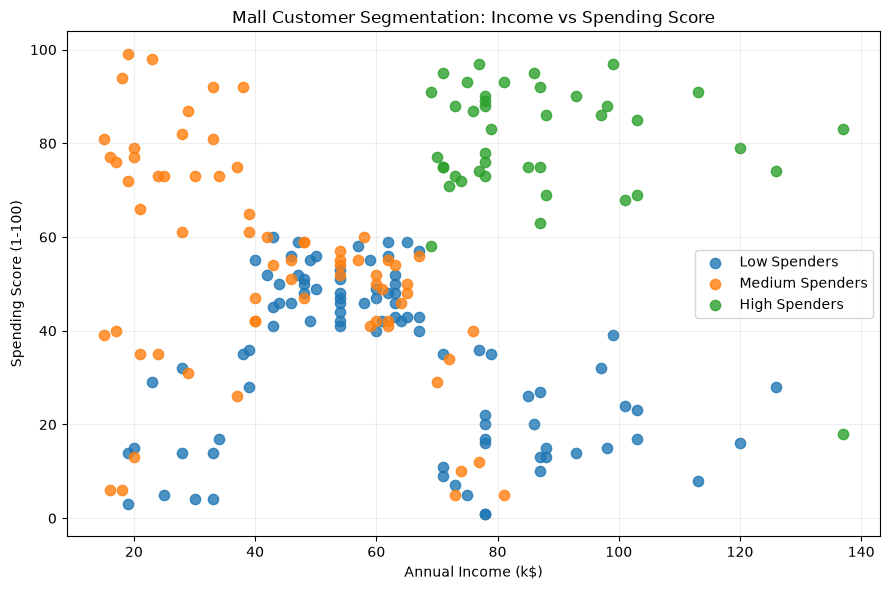

In [8]:
plt.figure(figsize=(9, 6))

for group in ["Low Spenders", "Medium Spenders", "High Spenders"]:
    subset = results[results["Customer Group"] == group]
    plt.scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=group,
        s=55,
        alpha=0.8
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segmentation: Income vs Spending Score")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 9. Visualize Age vs Spending Score

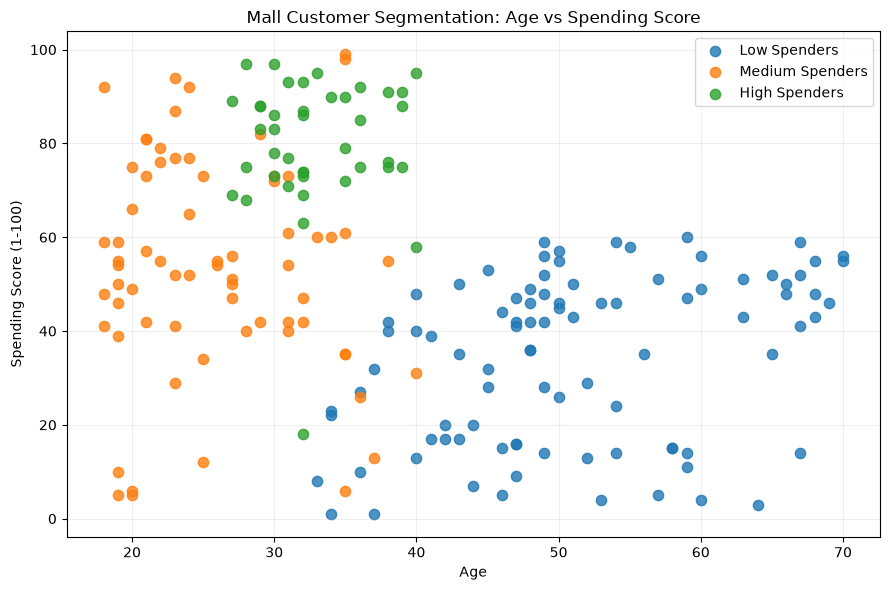

In [9]:
plt.figure(figsize=(9, 6))

for group in ["Low Spenders", "Medium Spenders", "High Spenders"]:
    subset = results[results["Customer Group"] == group]
    plt.scatter(
        subset["Age"],
        subset["Spending Score (1-100)"],
        label=group,
        s=55,
        alpha=0.8
    )

plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segmentation: Age vs Spending Score")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Visualize All Three Features (3D Scatter Plot)

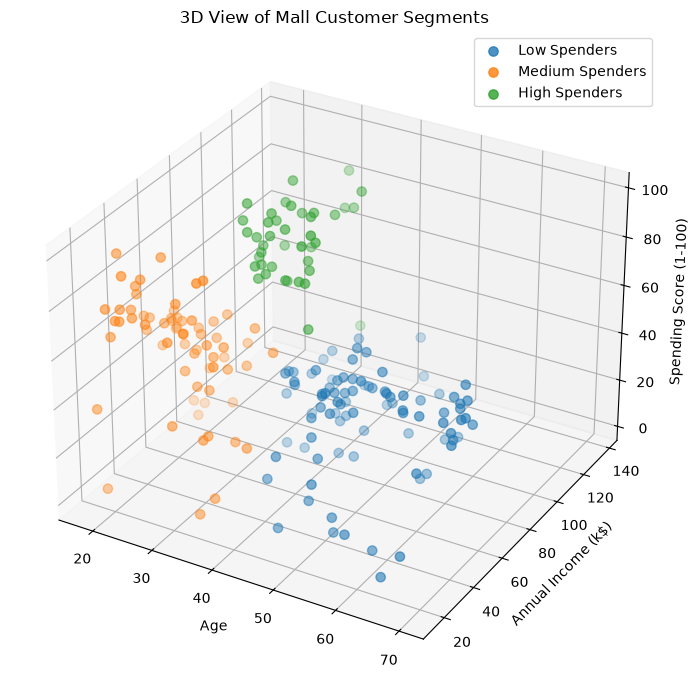

In [10]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for group in ["Low Spenders", "Medium Spenders", "High Spenders"]:
    subset = results[results["Customer Group"] == group]
    ax.scatter(
        subset["Age"],
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=group,
        s=45,
        alpha=0.8
    )

ax.set_xlabel("Age")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel("Spending Score (1-100)")
ax.set_title("3D View of Mall Customer Segments")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Apply PCA for a 2D Cluster View

Explained variance ratio: [0.4427 0.3331]
Total variance retained by two components: 77.57%


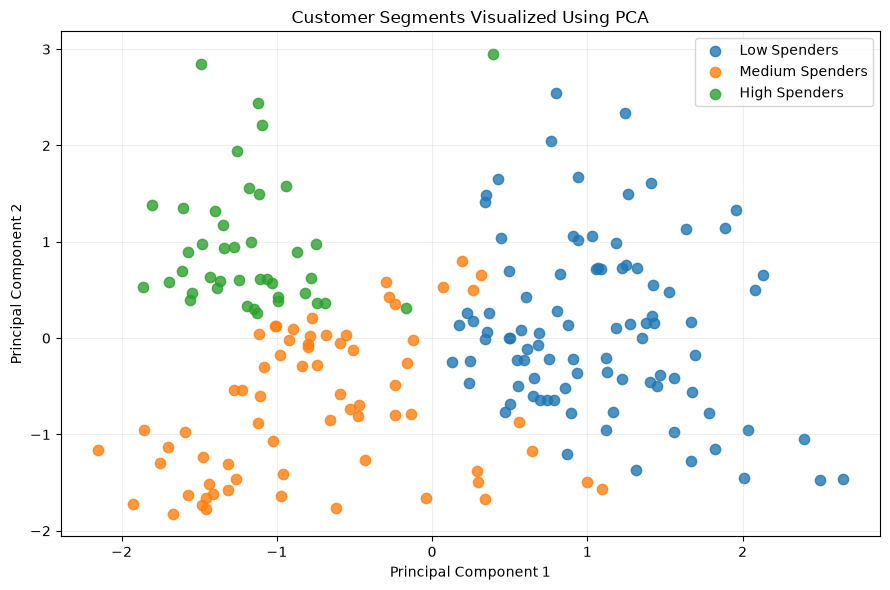

In [11]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

results["PCA1"] = X_pca[:, 0]
results["PCA2"] = X_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print(f"Total variance retained by two components: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

plt.figure(figsize=(9, 6))
for group in ["Low Spenders", "Medium Spenders", "High Spenders"]:
    subset = results[results["Customer Group"] == group]
    plt.scatter(subset["PCA1"], subset["PCA2"], label=group, s=55, alpha=0.8)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments Visualized Using PCA")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Evaluate Clustering with Silhouette Score

In [12]:
silhouette = silhouette_score(X_scaled, clusters)
print(f"Silhouette Score: {silhouette:.3f}")
print("The silhouette score ranges from -1 to 1; a higher score generally indicates better-separated clusters.")

Silhouette Score: 0.358
The silhouette score ranges from -1 to 1; a higher score generally indicates better-separated clusters.


## 13. Save the Results

In [13]:
results.to_csv("mall_customer_segmentation_results.csv", index=False)
summary.to_csv("mall_customer_group_summary.csv")

print("Results saved to:")
print("- mall_customer_segmentation_results.csv")
print("- mall_customer_group_summary.csv")

display(results.head())

Results saved to:
- mall_customer_segmentation_results.csv
- mall_customer_group_summary.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),PredictedCluster,Customer Group,PCA1,PCA2
0,1,Male,19,15,39,0,Medium Spenders,-0.615720,-1.763481
1,2,Male,21,15,81,0,Medium Spenders,-1.665793,-1.820747
2,3,Female,20,16,6,0,Medium Spenders,0.337862,-1.674799
3,4,Female,23,16,77,0,Medium Spenders,-1.456573,-1.772430
4,5,Female,31,17,40,0,Medium Spenders,-0.038465,-1.662740


## 14. Business Insights
Use the summary table and charts to discuss how customer groups differ in age, annual income, and spending score.

- **Low Spenders:** customers in the cluster with the lowest average Spending Score.
- **Medium Spenders:** customers in the cluster with the middle average Spending Score.
- **High Spenders:** customers in the cluster with the highest average Spending Score.

These labels describe groups based on relative average spending scores. They do not prove that every customer in a group behaves identically.

## 15. Conclusion
K-Means clustering was applied to the Mall Customers dataset using Age, Annual Income, and Spending Score. The customers were divided into three groups and labelled according to each cluster's average Spending Score. Scatter plots and a PCA visualization help explore the customer segments, while the summary table supports business-oriented interpretation.

**References:** Scikit-learn documentation for `KMeans`, `StandardScaler`, `PCA`, and `silhouette_score`.
